In [26]:
# ============================================================
# INSURANCE CLAIM STATUS PREDICTION
# Decision Tree Classification
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

pd.set_option("display.max_columns", None)

sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("File loaded:", filename)
print("Dataset shape:", df.shape)

Saving Insurance claims data.csv to Insurance claims data.csv
File loaded: Insurance claims data.csv
Dataset shape: (58592, 41)


In [27]:
# ============================================================
# BASIC DATASET INFORMATION
# ============================================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nDataset information:")
df.info()

Number of rows: 58592
Number of columns: 41

Column names:
1. policy_id
2. subscription_length
3. vehicle_age
4. customer_age
5. region_code
6. region_density
7. segment
8. model
9. fuel_type
10. max_torque
11. max_power
12. engine_type
13. airbags
14. is_esc
15. is_adjustable_steering
16. is_tpms
17. is_parking_sensors
18. is_parking_camera
19. rear_brakes_type
20. displacement
21. cylinder
22. transmission_type
23. steering_type
24. turning_radius
25. length
26. width
27. gross_weight
28. is_front_fog_lights
29. is_rear_window_wiper
30. is_rear_window_washer
31. is_rear_window_defogger
32. is_brake_assist
33. is_power_door_locks
34. is_central_locking
35. is_power_steering
36. is_driver_seat_height_adjustable
37. is_day_night_rear_view_mirror
38. is_ecw
39. is_speed_alert
40. ncap_rating
41. claim_status

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Cou

In [28]:
# ============================================================
# DATA CLEANING
# ============================================================

print("Missing values before cleaning:")
missing = df.isnull().sum()

if missing.sum() == 0:
    print("No missing values found.")
else:
    display(missing[missing > 0])

print("\nDuplicate rows before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Remove rows where target is missing, if any
df = df.dropna(subset=["claim_status"])

print("\nDataset shape after cleaning:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Total missing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning:
No missing values found.

Duplicate rows before cleaning: 0

Dataset shape after cleaning: (58592, 41)
Duplicate rows after cleaning: 0
Total missing values after cleaning: 0


Target variable: claim_status

Target counts:


,count
claim_status,
0,54844
1,3748



Target percentages:


,Percentage
claim_status,
0,93.6
1,6.4


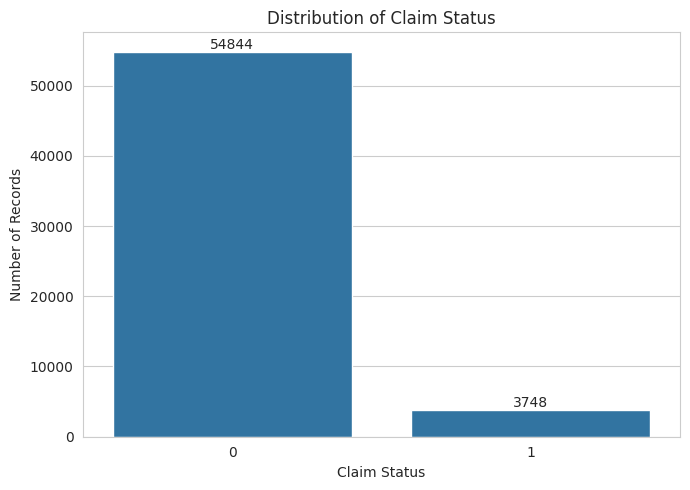

In [29]:
# ============================================================
# TARGET VARIABLE ANALYSIS
# ============================================================

target = "claim_status"

print("Target variable:", target)

print("\nTarget counts:")
display(df[target].value_counts())

print("\nTarget percentages:")
target_percent = (
    df[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(target_percent.to_frame("Percentage"))

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=target
)

plt.title("Distribution of Claim Status")
plt.xlabel("Claim Status")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# DESCRIPTIVE STATISTICS
# ============================================================

print("Numerical variables:")
display(df.describe().T)

print("\nCategorical variables:")
display(df.describe(include="object").T)

Numerical variables:


,count,mean,std,min,25%,50%,75%,max
subscription_length,58592.0,6.111688,4.142790,0.0,2.1,5.7,10.4,14.0
vehicle_age,58592.0,1.388473,1.134413,0.0,0.4,1.2,2.2,20.0
customer_age,58592.0,44.823935,6.935604,35.0,39.0,44.0,49.0,75.0
region_density,58592.0,18826.858667,17660.174792,290.0,6112.0,8794.0,27003.0,73430.0
airbags,58592.0,3.137066,1.832641,1.0,2.0,2.0,6.0,6.0
displacement,58592.0,1162.355851,266.304786,796.0,796.0,1197.0,1493.0,1498.0
cylinder,58592.0,3.626963,0.483616,3.0,3.0,4.0,4.0,4.0
turning_radius,58592.0,4.852893,0.228061,4.5,4.6,4.8,5.0,5.2
length,58592.0,3850.476891,311.457119,3445.0,3445.0,3845.0,3995.0,4300.0
width,58592.0,1672.233667,112.089135,1475.0,1515.0,1735.0,1755.0,1811.0



Categorical variables:


,count,unique,top,freq
policy_id,58592,58592,POL015043,1
region_code,58592,22,C8,13654
segment,58592,6,B2,18314
model,58592,11,M1,14948
fuel_type,58592,3,Petrol,20532
max_torque,58592,9,113Nm@4400rpm,17796
max_power,58592,9,88.50bhp@6000rpm,17796
engine_type,58592,11,F8D Petrol Engine,14948
is_esc,58592,2,No,40191
is_adjustable_steering,58592,2,Yes,35526


In [31]:
# ============================================================
# FEATURE TYPES
# ============================================================

# policy_id is an identifier, not a meaningful predictive feature
identifier_columns = ["policy_id"]

feature_columns = [
    col for col in df.columns
    if col not in identifier_columns + [target]
]

categorical_features = df[feature_columns].select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = df[feature_columns].select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Identifier columns removed from modelling:")
print(identifier_columns)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Identifier columns removed from modelling:
['policy_id']

Categorical features:
['region_code', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'transmission_type', 'steering_type', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']

Numerical features:
['subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'airbags', 'displacement', 'cylinder', 'turning_radius', 'length', 'width', 'gross_weight', 'ncap_rating']


In [32]:
# ============================================================
# DATASET / ASSIGNMENT ALIGNMENT
# ============================================================

print("""
IMPORTANT DATASET NOTE
----------------------

The assignment describes an insurance claim approval/rejection
problem and mentions variables such as:

- Claim amount
- Incident type
- Documentation status
- Customer history
- Policy type

The supplied Kaggle dataset does not contain explicit
approval/rejection fields or all of those variables.

The available binary target is:

    claim_status

Therefore, this project uses claim_status as the classification
target and predicts whether a policy record has claim status 0
or 1.

The available policy, customer, regional and vehicle-related
attributes are used as predictors.

No unavailable variables are artificially created.
""")


IMPORTANT DATASET NOTE
----------------------

The assignment describes an insurance claim approval/rejection
problem and mentions variables such as:

- Claim amount
- Incident type
- Documentation status
- Customer history
- Policy type

The supplied Kaggle dataset does not contain explicit
approval/rejection fields or all of those variables.

The available binary target is:

    claim_status

Therefore, this project uses claim_status as the classification
target and predicts whether a policy record has claim status 0
or 1.

The available policy, customer, regional and vehicle-related
attributes are used as predictors.

No unavailable variables are artificially created.



In [33]:
# ============================================================
# EDA HELPER
# ============================================================

def claim_rate_table(data, column):
    result = (
        data.groupby(column)["claim_status"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )

    result["claim_rate_percent"] = result["mean"] * 100

    return result


def plot_claim_rate(data, column, figsize=(10, 5), rotation=45):

    result = claim_rate_table(data, column)

    plt.figure(figsize=figsize)

    ax = sns.barplot(
        x=result.index.astype(str),
        y=result["claim_rate_percent"].values
    )

    plt.title(f"Claim Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Claim Rate (%)")
    plt.xticks(rotation=rotation)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3,
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

    return result


CLAIM RATE BY segment


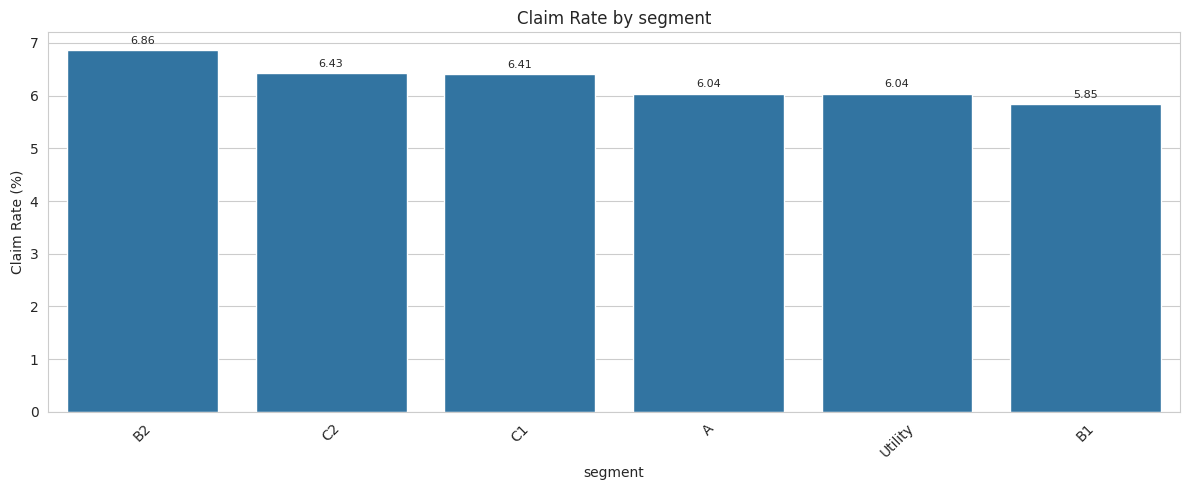

,count,mean,claim_rate_percent
segment,,,
B2,18314,0.068581,6.858141
C2,14018,0.064275,6.427450
C1,3557,0.064099,6.409896
A,17321,0.060389,6.038912
Utility,1209,0.060380,6.038048
B1,4173,0.058471,5.847112



CLAIM RATE BY fuel_type


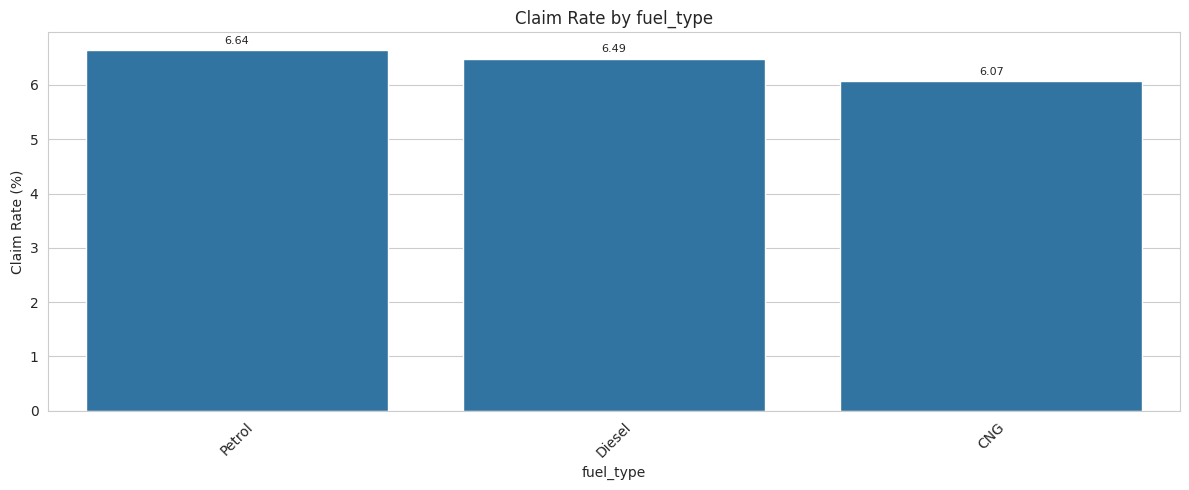

,count,mean,claim_rate_percent
fuel_type,,,
Petrol,20532,0.066384,6.638418
Diesel,17730,0.064862,6.486182
CNG,20330,0.060748,6.074766



CLAIM RATE BY model


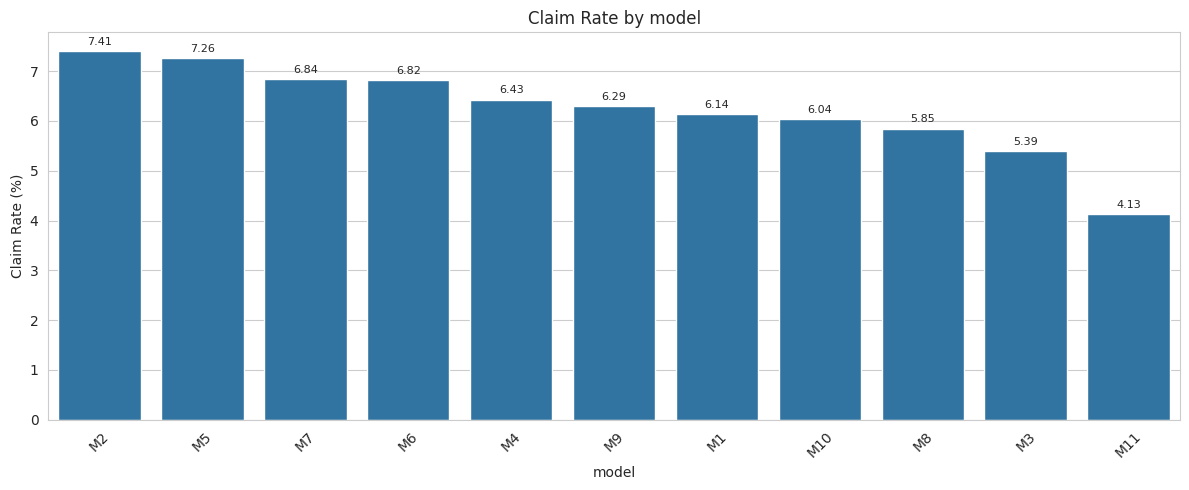

,count,mean,claim_rate_percent
model,,,
M2,1080,0.074074,7.407407
M5,1598,0.072591,7.259074
M7,2940,0.068367,6.836735
M6,13776,0.068162,6.816202
M4,14018,0.064275,6.427450
M9,2114,0.062914,6.291391
M1,14948,0.061413,6.141290
M10,1209,0.060380,6.038048
M8,4173,0.058471,5.847112



CLAIM RATE BY transmission_type


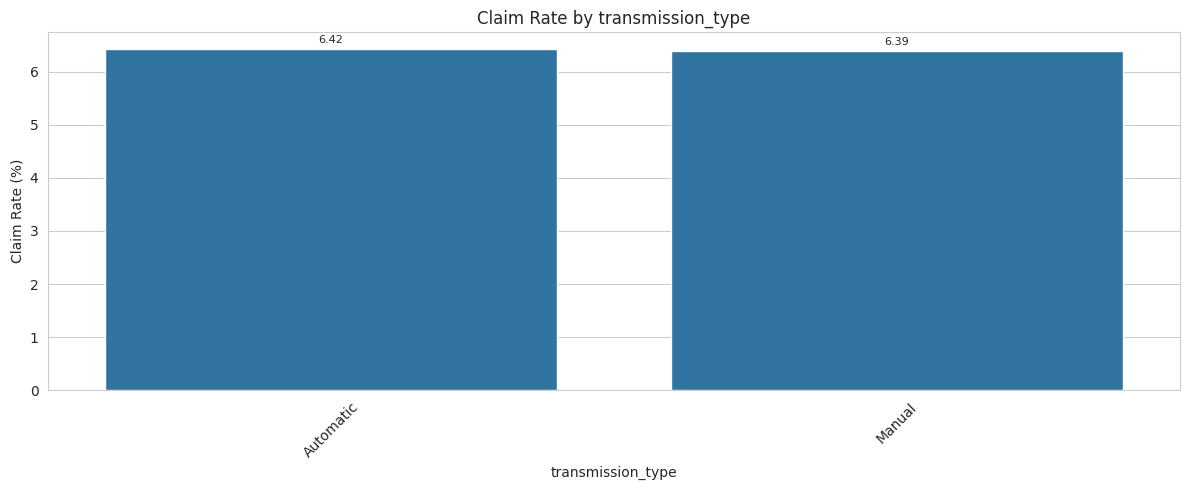

,count,mean,claim_rate_percent
transmission_type,,,
Automatic,20411,0.064181,6.418108
Manual,38181,0.063854,6.385375



CLAIM RATE BY steering_type


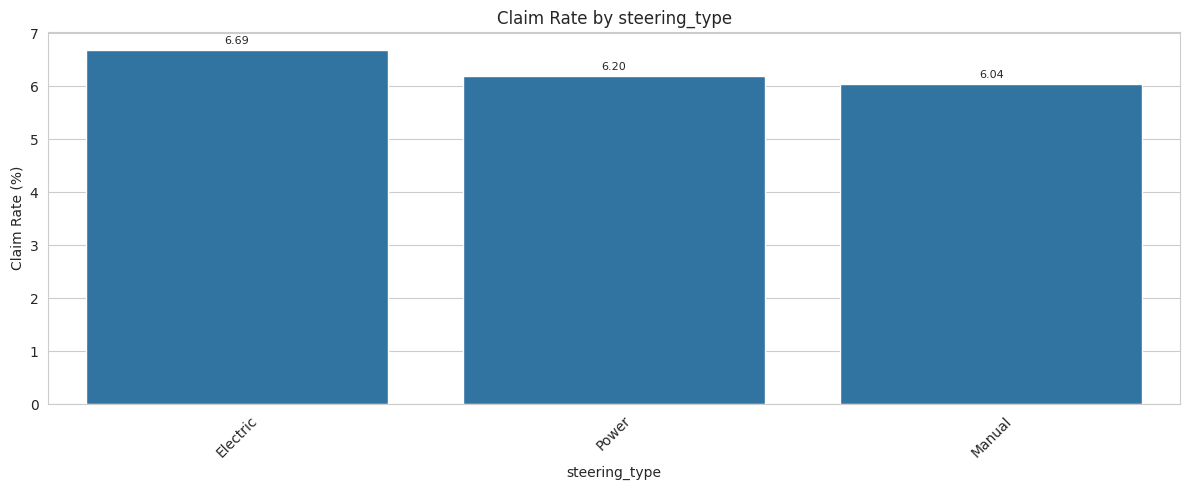

,count,mean,claim_rate_percent
steering_type,,,
Electric,23881,0.066873,6.687325
Power,33502,0.062026,6.202615
Manual,1209,0.060380,6.038048



CLAIM RATE BY region_code


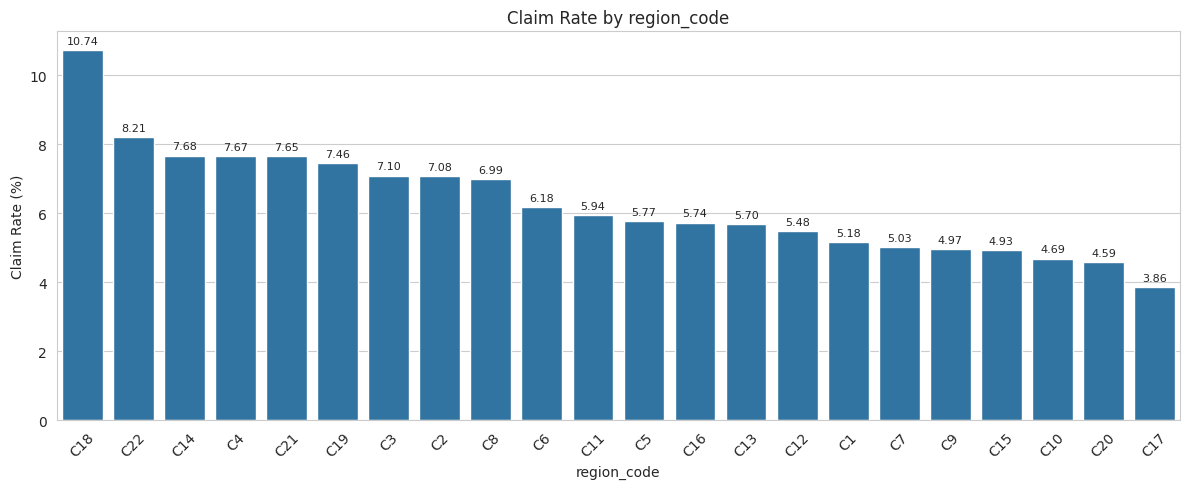

,count,mean,claim_rate_percent
region_code,,,
C18,242,0.107438,10.743802
C22,207,0.082126,8.212560
C14,3660,0.076776,7.677596
C4,665,0.076692,7.669173
C21,379,0.076517,7.651715
C19,952,0.074580,7.457983
C3,6101,0.070972,7.097197
C2,7342,0.070825,7.082539
C8,13654,0.069870,6.986964



CLAIM RATE BY engine_type


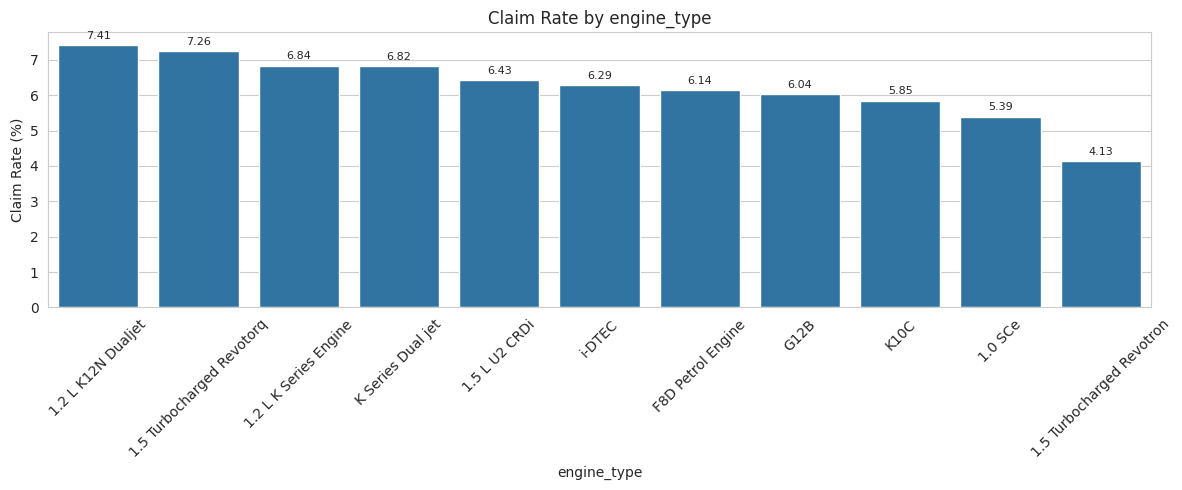

,count,mean,claim_rate_percent
engine_type,,,
1.2 L K12N Dualjet,1080,0.074074,7.407407
1.5 Turbocharged Revotorq,1598,0.072591,7.259074
1.2 L K Series Engine,2940,0.068367,6.836735
K Series Dual jet,13776,0.068162,6.816202
1.5 L U2 CRDi,14018,0.064275,6.427450
i-DTEC,2114,0.062914,6.291391
F8D Petrol Engine,14948,0.061413,6.141290
G12B,1209,0.060380,6.038048
K10C,4173,0.058471,5.847112



CLAIM RATE BY rear_brakes_type


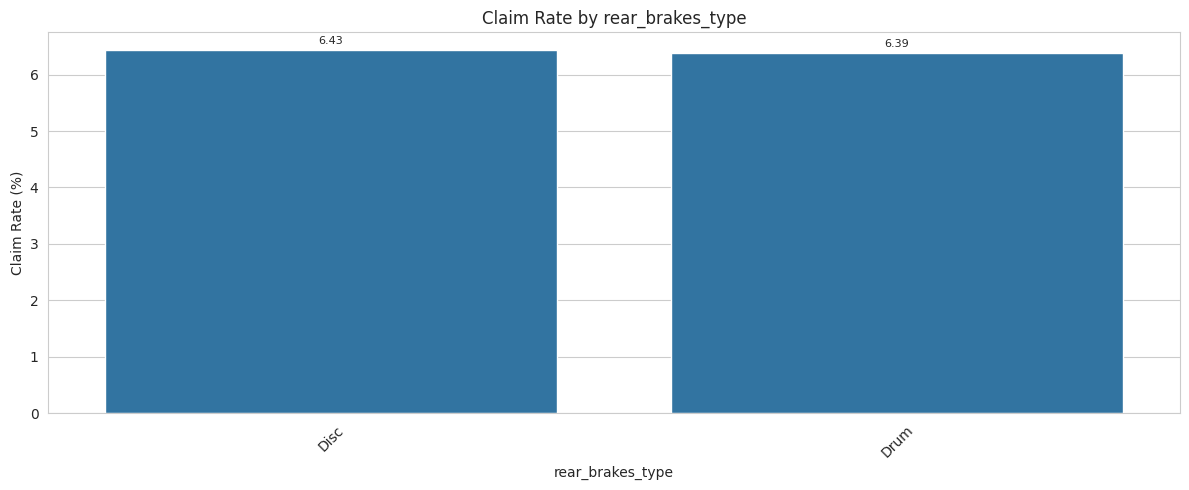

,count,mean,claim_rate_percent
rear_brakes_type,,,
Disc,14018,0.064275,6.427450
Drum,44574,0.063871,6.387132


In [34]:
# ============================================================
# CLAIM RATE BY CATEGORICAL FEATURES
# ============================================================

categorical_eda_features = [
    col for col in [
        "segment",
        "fuel_type",
        "model",
        "transmission_type",
        "steering_type",
        "region_code",
        "engine_type",
        "rear_brakes_type"
    ]
    if col in df.columns
]

for col in categorical_eda_features:

    print(f"\n{'='*60}")
    print(f"CLAIM RATE BY {col}")
    print(f"{'='*60}")

    display(plot_claim_rate(
        df,
        col,
        figsize=(12, 5)
    ))

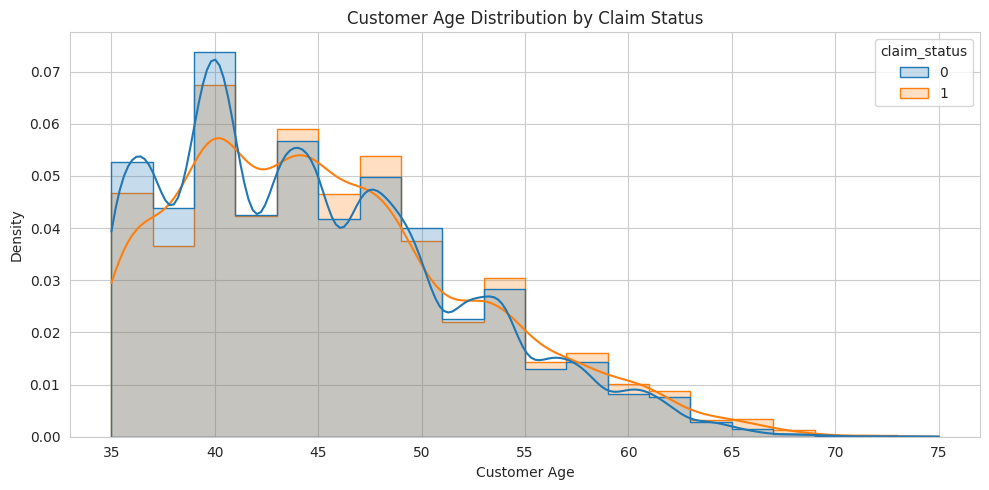

In [35]:
# ============================================================
# CUSTOMER AGE VS CLAIM STATUS
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="customer_age",
    hue="claim_status",
    bins=20,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Customer Age Distribution by Claim Status")
plt.xlabel("Customer Age")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

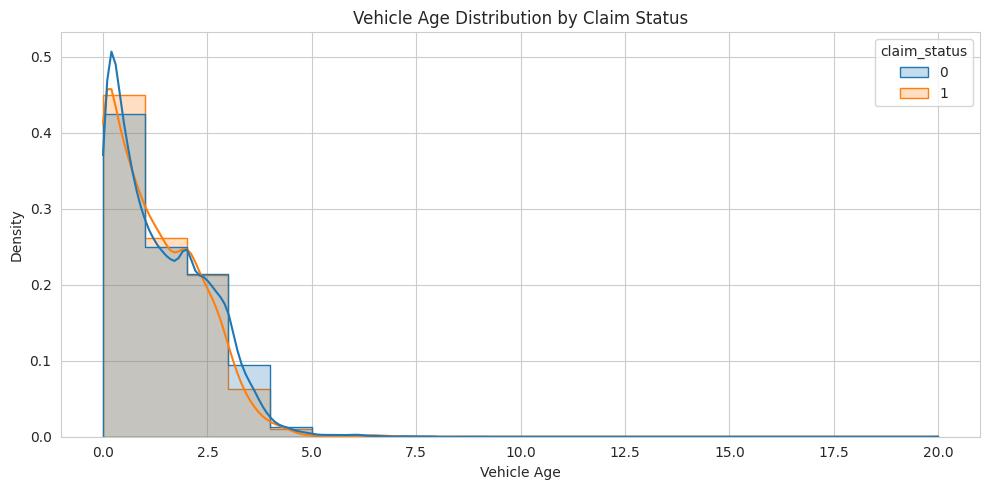

In [36]:
# ============================================================
# VEHICLE AGE VS CLAIM STATUS
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="vehicle_age",
    hue="claim_status",
    bins=20,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Vehicle Age Distribution by Claim Status")
plt.xlabel("Vehicle Age")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

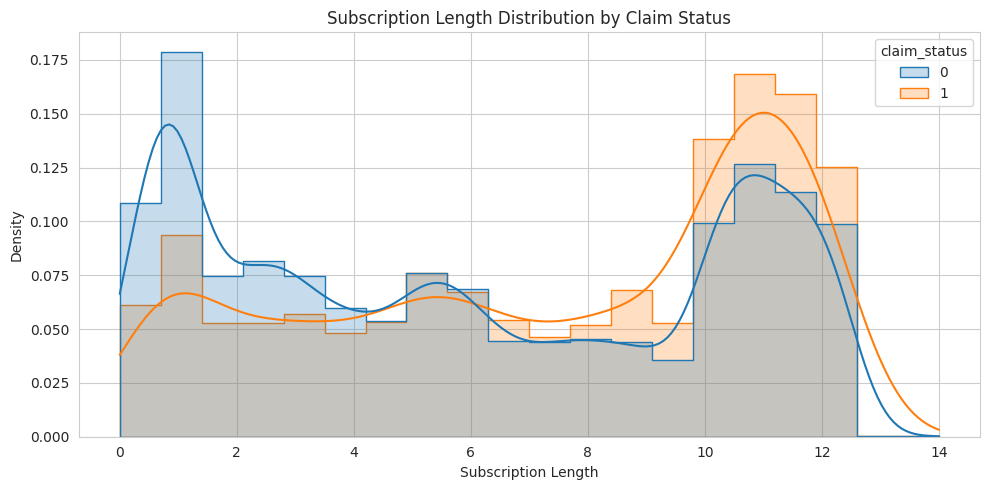

In [37]:
# ============================================================
# POLICY/SUBSCRIPTION DURATION VS CLAIM STATUS
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="subscription_length",
    hue="claim_status",
    bins=20,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Subscription Length Distribution by Claim Status")
plt.xlabel("Subscription Length")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

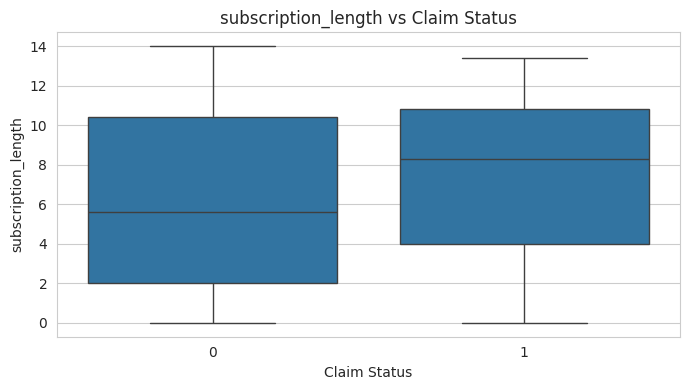

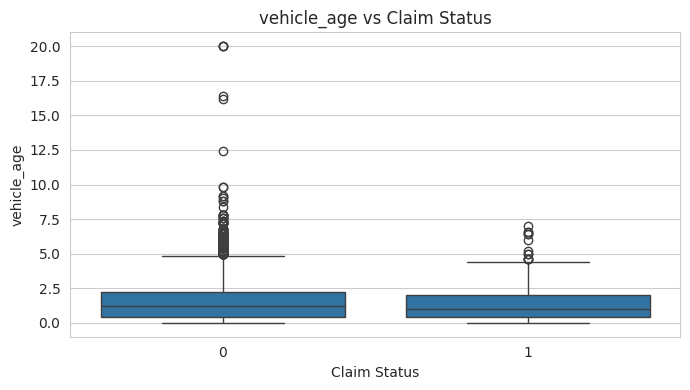

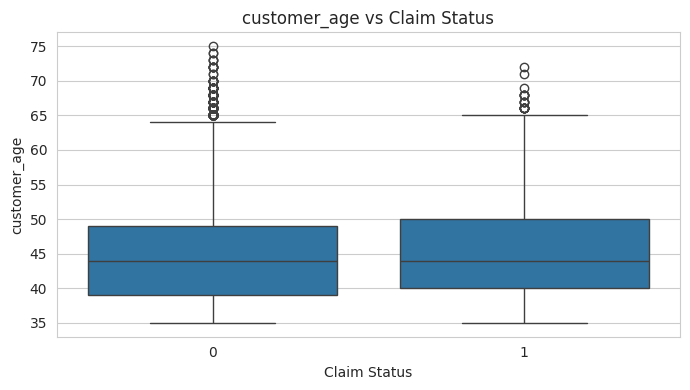

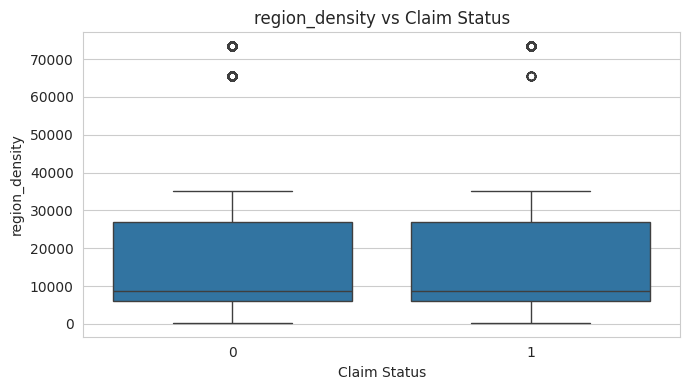

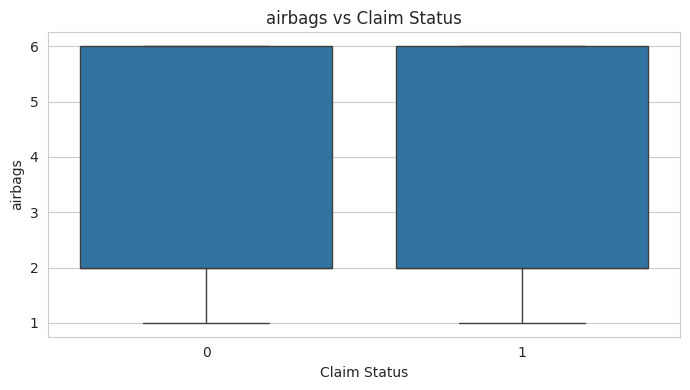

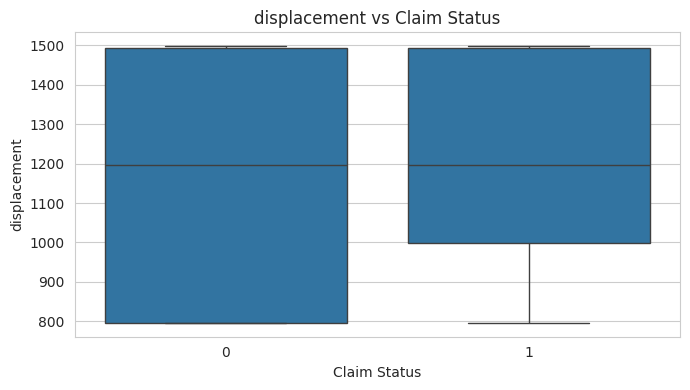

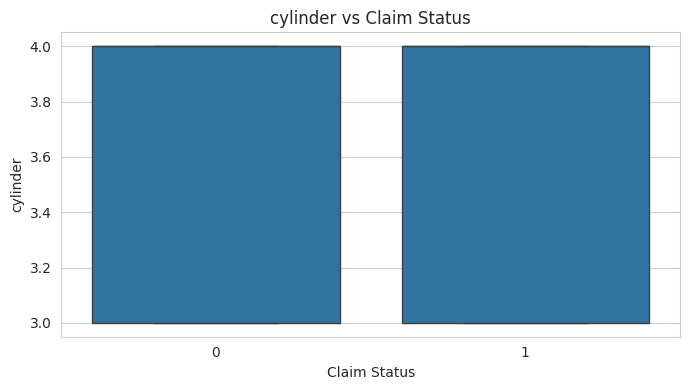

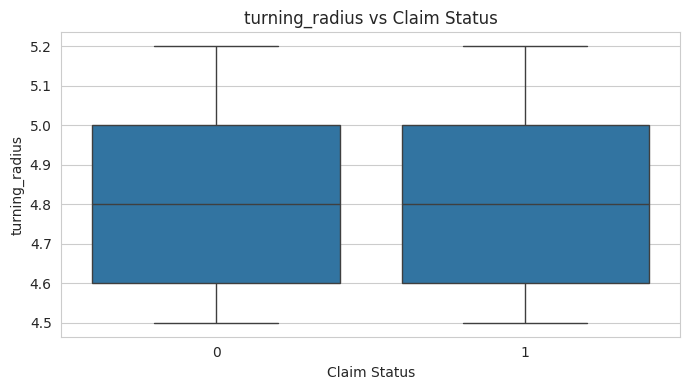

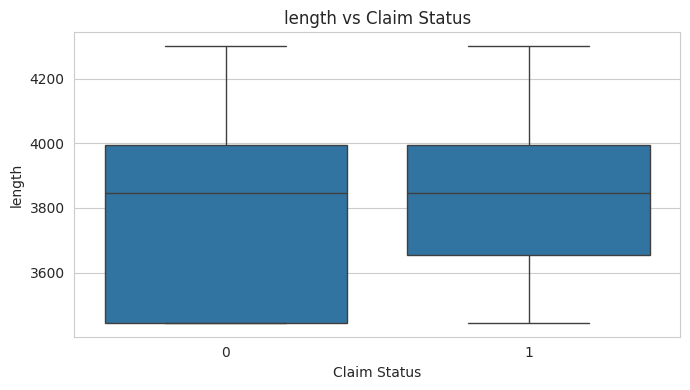

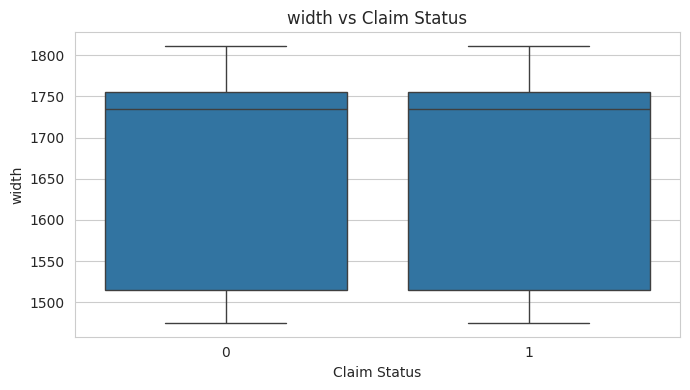

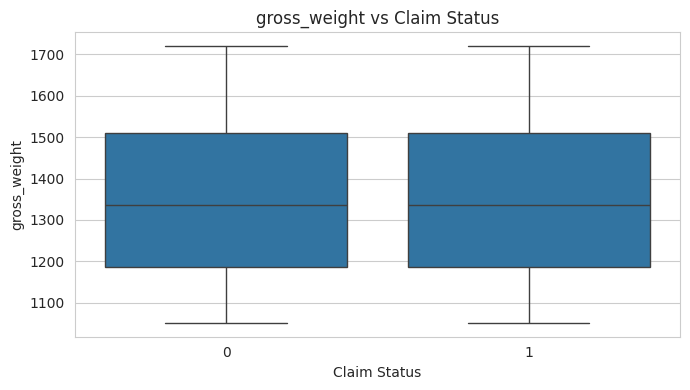

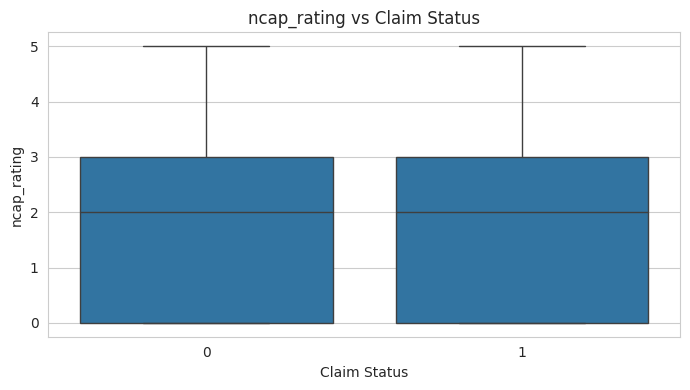

In [38]:
# ============================================================
# NUMERICAL FEATURES VS CLAIM STATUS
# ============================================================

eda_numerical = [
    col for col in [
        "subscription_length",
        "vehicle_age",
        "customer_age",
        "region_density",
        "airbags",
        "displacement",
        "cylinder",
        "turning_radius",
        "length",
        "width",
        "gross_weight",
        "ncap_rating"
    ]
    if col in df.columns
]

for col in eda_numerical:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="claim_status",
        y=col
    )

    plt.title(f"{col} vs Claim Status")
    plt.xlabel("Claim Status")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

In [39]:
# ============================================================
# NUMERICAL FEATURE COMPARISON
# ============================================================

comparison = df.groupby("claim_status")[eda_numerical].mean().T

comparison.columns = [
    "No Claim (0)",
    "Claim (1)"
]

display(comparison)

,No Claim (0),Claim (1)
subscription_length,6.026415,7.359472
vehicle_age,1.396827,1.266222
customer_age,44.783623,45.413821
region_density,18909.073445,17623.820438
airbags,3.135730,3.156617
displacement,1161.821348,1170.177161
cylinder,3.625264,3.651814
turning_radius,4.852730,4.855269
length,3849.948107,3858.214514
width,1671.942200,1676.498666


In [40]:
# ============================================================
# SAFETY FEATURES AND CLAIM RATE
# ============================================================

safety_features = [
    col for col in [
        "is_esc",
        "is_adjustable_steering",
        "is_tpms",
        "is_parking_sensors",
        "is_parking_camera",
        "is_front_fog_lights",
        "is_rear_window_wiper",
        "is_rear_window_washer",
        "is_rear_window_defogger",
        "is_brake_assist",
        "is_power_door_locks",
        "is_central_locking",
        "is_power_steering",
        "is_driver_seat_height_adjustable",
        "is_day_night_rear_view_mirror",
        "is_ecw",
        "is_speed_alert"
    ]
    if col in df.columns
]

safety_results = []

for col in safety_features:

    grouped = df.groupby(col)["claim_status"].mean() * 100

    for category, rate in grouped.items():

        safety_results.append({
            "Feature": col,
            "Value": category,
            "Claim Rate (%)": rate
        })

safety_results = pd.DataFrame(safety_results)

display(safety_results)

,Feature,Value,Claim Rate (%)
0,is_esc,No,6.347192
1,is_esc,Yes,6.505081
2,is_adjustable_steering,No,5.974161
3,is_adjustable_steering,Yes,6.671170
4,is_tpms,No,6.387132
5,is_tpms,Yes,6.427450
6,is_parking_sensors,No,5.394016
7,is_parking_sensors,Yes,6.439104
8,is_parking_camera,No,6.413847
9,is_parking_camera,Yes,6.370150


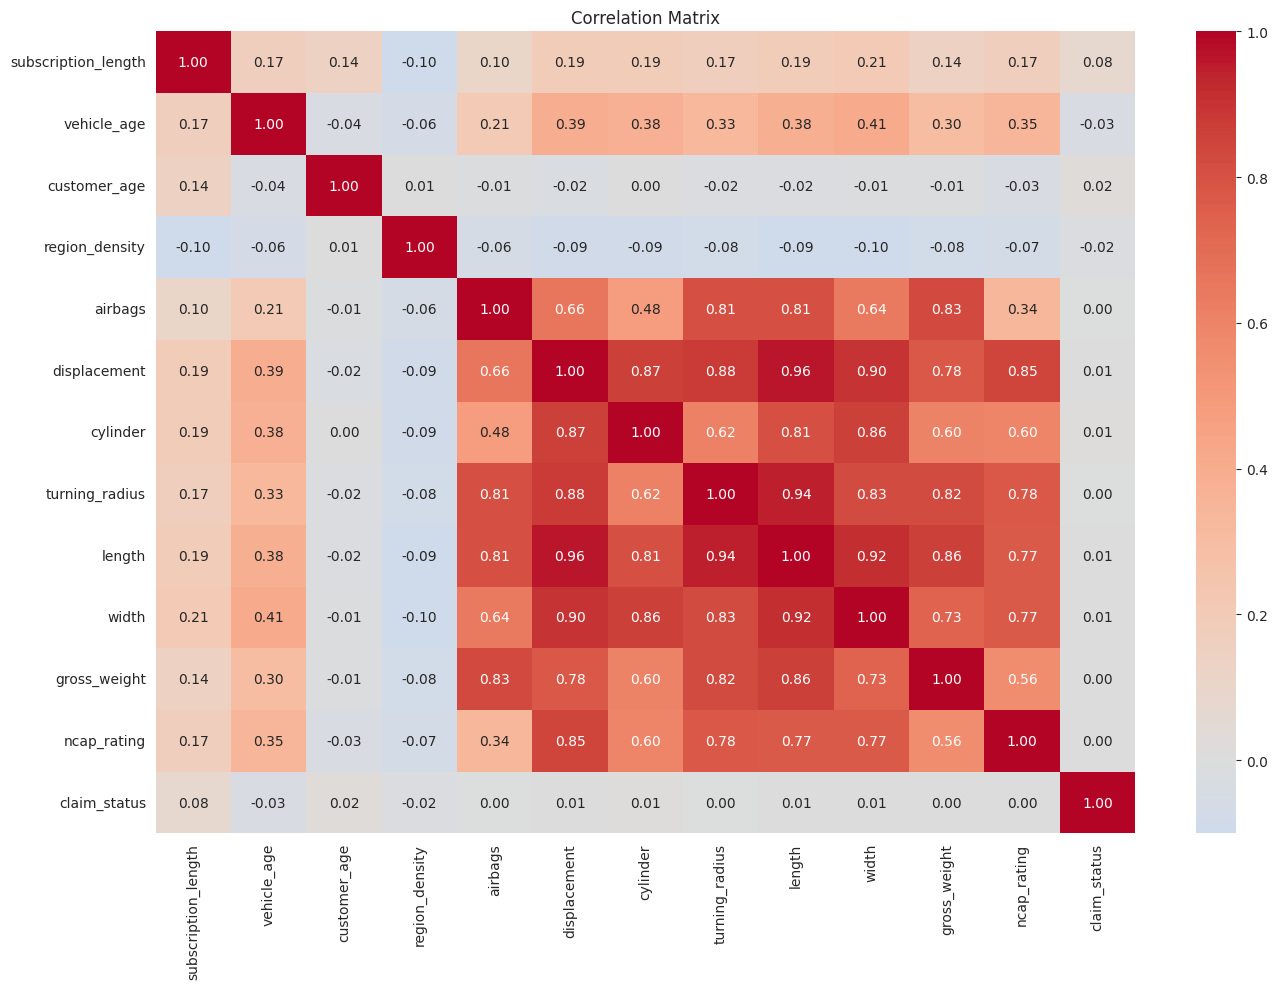

In [41]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

correlation_features = eda_numerical + ["claim_status"]

correlation = df[correlation_features].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# CORRELATION WITH CLAIM STATUS
# ============================================================

target_correlation = (
    correlation["claim_status"]
    .drop("claim_status")
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
)

display(
    target_correlation.to_frame(
        "Correlation with Claim Status"
    )
)

,Correlation with Claim Status
subscription_length,0.078738
vehicle_age,-0.028172
customer_age,0.022234
region_density,-0.017808
cylinder,0.013434
width,0.009947
displacement,0.007678
length,0.006495
gross_weight,0.003894
ncap_rating,0.003800


In [43]:
# ============================================================
# CORRELATION WITH CLAIM STATUS
# ============================================================

target_correlation = (
    correlation["claim_status"]
    .drop("claim_status")
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
)

display(
    target_correlation.to_frame(
        "Correlation with Claim Status"
    )
)

,Correlation with Claim Status
subscription_length,0.078738
vehicle_age,-0.028172
customer_age,0.022234
region_density,-0.017808
cylinder,0.013434
width,0.009947
displacement,0.007678
length,0.006495
gross_weight,0.003894
ncap_rating,0.003800


In [45]:
# ============================================================
# PREPARE FEATURES (X) AND TARGET (y)
# ============================================================

target = "claim_status"

# Remove ID column because it is just an identifier
drop_columns = ["policy_id", target]

X = df.drop(columns=drop_columns)
y = df[target].astype(int)

print("Features (X):", X.shape)
print("Target (y):", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(
    (y.value_counts(normalize=True) * 100).round(2)
)

Features (X): (58592, 39)
Target (y): (58592,)

Feature columns:
['subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'ncap_rating']

Target distribution:
claim_status
0    54844
1     3748
Name: count, dtype: int64

Target percentage:
claim_status
0    93.6
1     6.4
Name: proportion, dtype: float64


In [46]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 46873
Testing samples: 11719

Training target distribution:
claim_status
0    43875
1     2998
Name: count, dtype: int64

Testing target distribution:
claim_status
0    10969
1      750
Name: count, dtype: int64


In [47]:
# ============================================================
# PREPROCESSING
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 27
Numerical features: 12


In [48]:
# ============================================================
# PREPROCESSING
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 27
Numerical features: 12


In [49]:
# ============================================================
# DECISION TREE CLASSIFIER
# ============================================================

decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", decision_tree)
    ]
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [50]:
# ============================================================
# MODEL PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [51]:
# ============================================================
# MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

pr_auc = average_precision_score(
    y_test,
    y_probability
)

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy,
        balanced_accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc
    ]
})

metrics["Score"] = metrics["Score"].round(4)

display(metrics)

,Metric,Score
0,Accuracy,0.5388
1,Balanced Accuracy,0.6126
2,Precision,0.0917
3,Recall,0.6973
4,F1-Score,0.1621
5,ROC-AUC,0.6338
6,PR-AUC,0.0962


In [52]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Claim (0)",
            "Claim (1)"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

No Claim (0)       0.96      0.53      0.68     10969
   Claim (1)       0.09      0.70      0.16       750

    accuracy                           0.54     11719
   macro avg       0.53      0.61      0.42     11719
weighted avg       0.91      0.54      0.65     11719



Confusion Matrix:
[[5791 5178]
 [ 227  523]]


<Figure size 700x600 with 0 Axes>

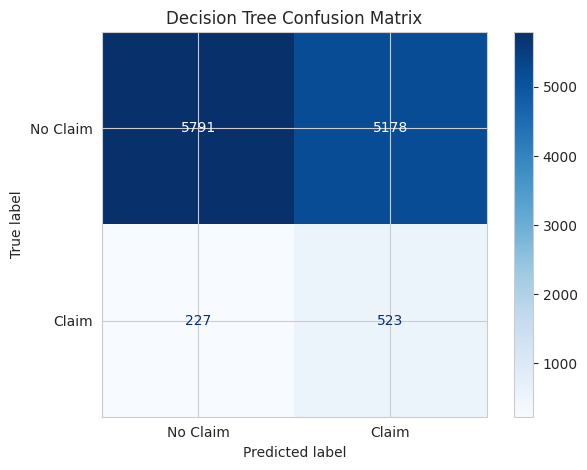

In [53]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Claim", "Claim"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

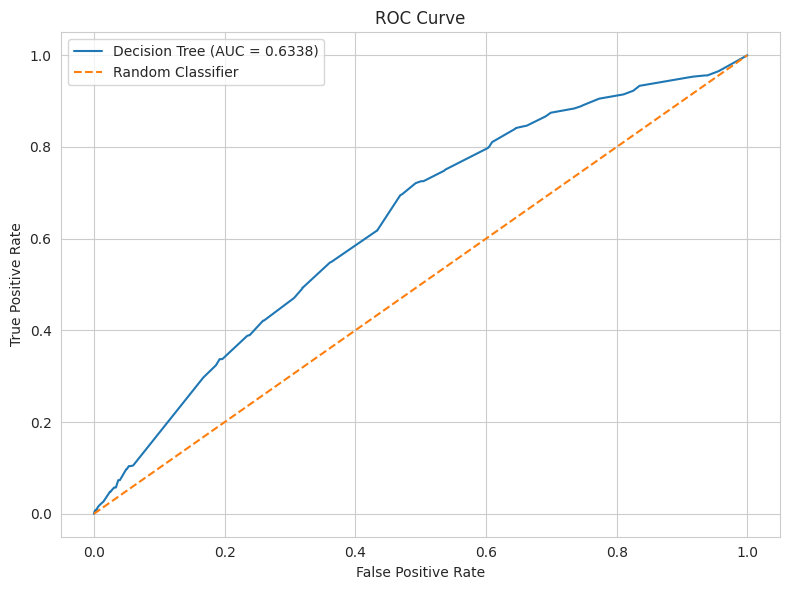

In [54]:
# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.tight_layout()
plt.show()

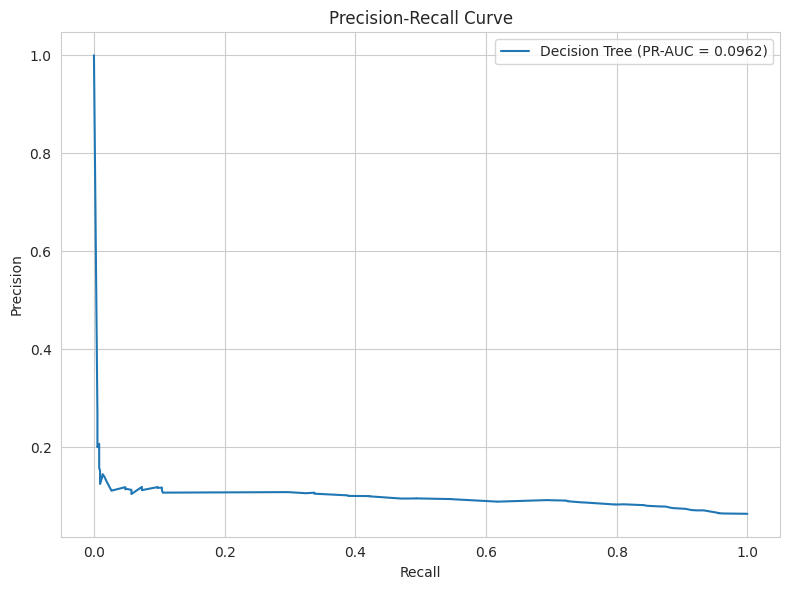

In [55]:
# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Decision Tree (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

trained_preprocessor = model.named_steps["preprocessor"]
trained_tree = model.named_steps["classifier"]

# Get transformed feature names
feature_names = trained_preprocessor.get_feature_names_out()

importance = trained_tree.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Most Important Features:")

display(
    feature_importance.head(20)
)

Top 20 Most Important Features:


,Feature,Importance
112,numerical__subscription_length,0.342446
113,numerical__vehicle_age,0.302273
114,numerical__customer_age,0.090704
115,numerical__region_density,0.049140
122,numerical__gross_weight,0.044220
120,numerical__length,0.036430
117,numerical__displacement,0.019045
10,categorical__region_code_C19,0.009716
5,categorical__region_code_C14,0.009395
9,categorical__region_code_C18,0.009382


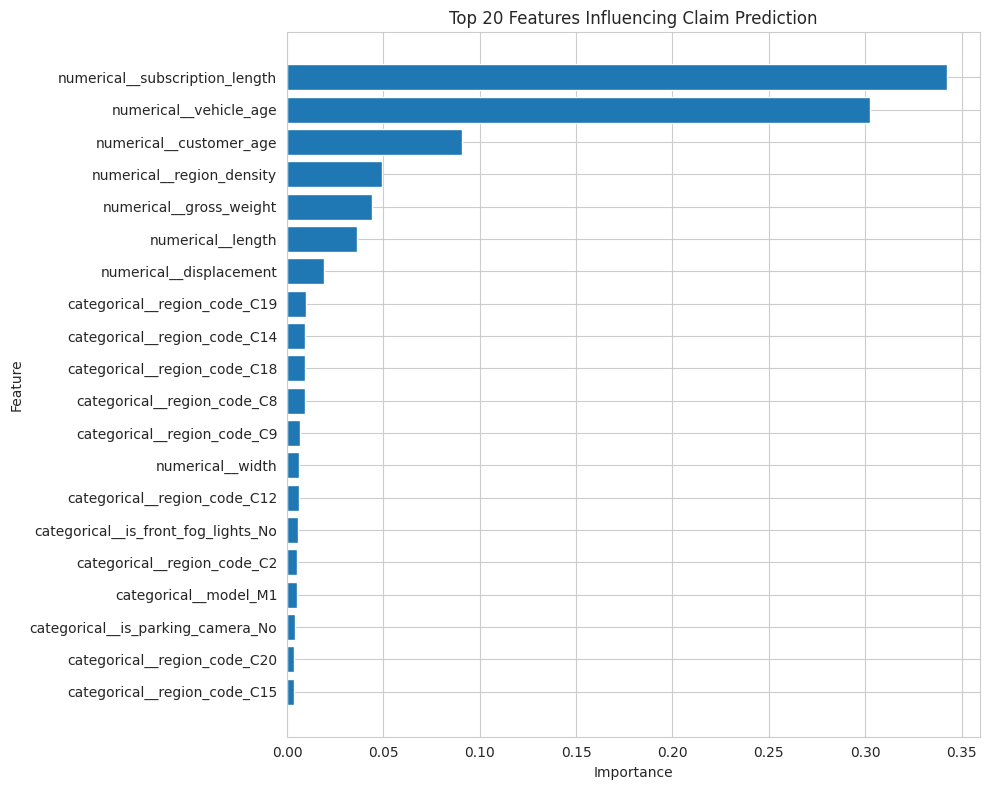

In [57]:
# ============================================================
# TOP FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Claim Prediction")

plt.tight_layout()
plt.show()

In [58]:
# ============================================================
# SAVE MODEL RESULTS
# ============================================================

metrics.to_csv(
    "insurance_model_metrics.csv",
    index=False
)

feature_importance.to_csv(
    "insurance_feature_importance.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [59]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("=" * 70)
print("INSURANCE CLAIM STATUS PREDICTION — FINAL RESULTS")
print("=" * 70)

print(f"Dataset size: {df.shape[0]:,} rows × {df.shape[1]} columns")

print(f"\nAccuracy          : {accuracy:.4f}")
print(f"Balanced Accuracy : {balanced_accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1-Score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"PR-AUC             : {pr_auc:.4f}")

print("\nTop 10 predictive features:")

display(
    feature_importance.head(10)
)

print("""
INTERPRETATION:

The Decision Tree predicts the binary claim_status outcome.
Because the target is imbalanced, accuracy should not be
considered alone. Precision, recall, F1-score, balanced
accuracy, ROC-AUC and PR-AUC provide a more complete assessment.

The feature-importance results identify the policy, customer,
regional and vehicle characteristics that contribute most
strongly to the model's predictions.

NOTE:
The supplied Kaggle dataset contains claim_status rather than
an explicit claim approval/rejection variable. Therefore,
the model predicts claim status rather than literal claim
approval.
""")

INSURANCE CLAIM STATUS PREDICTION — FINAL RESULTS
Dataset size: 58,592 rows × 41 columns

Accuracy          : 0.5388
Balanced Accuracy : 0.6126
Precision         : 0.0917
Recall            : 0.6973
F1-Score          : 0.1621
ROC-AUC           : 0.6338
PR-AUC             : 0.0962

Top 10 predictive features:


,Feature,Importance
112,numerical__subscription_length,0.342446
113,numerical__vehicle_age,0.302273
114,numerical__customer_age,0.090704
115,numerical__region_density,0.049140
122,numerical__gross_weight,0.044220
120,numerical__length,0.036430
117,numerical__displacement,0.019045
10,categorical__region_code_C19,0.009716
5,categorical__region_code_C14,0.009395
9,categorical__region_code_C18,0.009382



INTERPRETATION:

The Decision Tree predicts the binary claim_status outcome.
Because the target is imbalanced, accuracy should not be
considered alone. Precision, recall, F1-score, balanced
accuracy, ROC-AUC and PR-AUC provide a more complete assessment.

The feature-importance results identify the policy, customer,
regional and vehicle characteristics that contribute most
strongly to the model's predictions.

NOTE:
The supplied Kaggle dataset contains claim_status rather than
an explicit claim approval/rejection variable. Therefore,
the model predicts claim status rather than literal claim
approval.

